# Bài II – Mô hình dự báo khách hàng good / bad

**Mục tiêu:** dự báo xác suất một người nộp đơn vay trở thành khách hàng *bad* (`flag_bad = 1`), dựa trên demographic data (`de_`), phone data (`ph_`) và Facebook data (`fb_`).

1. **Khám phá dữ liệu**: dữ liệu trông thế nào, có vấn đề gì?
2. **Làm sạch và tạo biến**: biến dữ liệu thô thành tín hiệu có ý nghĩa
3. **Chia dữ liệu theo thời gian**: training set trên tháng 1–5, test set trên tháng 6–7
4. **Chọn biến bằng WOE / IV**
5. **Huấn luyện 2 mô hình**: Logistic Regression (scorecard) và Gradient Boosting
6. **Đánh giá và chọn mô hình**: AUC / AR / KS, overfitting, hiệu chuẩn (Hosmer-Lemeshow), độ ổn định (PSI)

Mỗi bước có phần **Quyết định**, ghi rõ đã chọn gì và vì sao.

## 0. Data preparation

In [1]:
import ast
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42

import warnings
# pandas báo cảnh báo vô hại khi chia nhóm có ô trống (NaN); kết quả không bị ảnh hưởng
warnings.filterwarnings("ignore", category=RuntimeWarning, message="invalid value encountered in cast")

import os
DATA_PATH = "data.csv" if os.path.exists("data.csv") else "../data.csv"
raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Số dòng, số cột:", raw.shape)
print("Tỷ lệ bad: {:.2%}".format(raw["flag_bad"].mean()))

Số dòng, số cột: (41022, 22)
Tỷ lệ bad: 12.97%


In [2]:
raw.head()

,index,flag_bad,de_age,de_gender,de_date_joined,de_num_friends,de_monthly_salary,de_employment_type,de_employment_duration,de_accomodation_type,de_education,de_marital_status,de_children,ph_total_contacts,ph_other_device_info,ph_call_log_stats,ph_country_code,ph_app_list,fb_gender,fb_dob,fb_last_updated_date,fb_relation
0,0,0,26,1,08/04/2018 14:50,2535,3000000,1,51,4,2,2,0,66,"{""device_codename"": ""HM2014817"", ""brand"": ""Xia...","{""percent_incoming_nighttime"": 1.83, ""percent_...",id,"['com.google.android.music', 'com.facebook.orc...",male,11/23/1991,2017-12-21T04:38:00+0000,Married
1,1,0,22,1,02/01/2018 17:17,685,4000000,1,28,4,4,1,0,69,"{""device_codename"": ""A1601"", ""brand"": ""OPPO""}","{""percent_incoming_nighttime"": 0.0, ""percent_o...",id,"['com.google.android.instantapps.supervisor', ...",male,01/20/1995,2017-11-25T17:23:09+0000,NaN
2,2,1,32,1,01/01/2018 16:39,1765,7000000,1,35,4,4,2,2,315,"{""device_codename"": ""A1601"", ""brand"": ""OPPO""}","{""percent_incoming_nighttime"": 6.65, ""percent_...",id,"['com.tencent.ibg.joox', 'com.mrgames.larvaact...",male,10/13/1985,2017-12-23T18:05:57+0000,Married
3,3,0,31,2,04/01/2018 22:36,407,20000000,3,37,4,3,2,2,84,"{""device_codename"": ""A1601"", ""brand"": ""OPPO""}","{""percent_incoming_nighttime"": 0.0, ""percent_o...",id,"['com.kfit.fave', 'app.bpjs.mobile', 'com.redd...",female,07/27/1986,2017-12-05T09:37:19+0000,Married
4,4,0,27,1,02/01/2018 18:12,3064,3000000,1,36,4,3,1,0,0,"{""device_codename"": ""1609"", ""brand"": ""vivo""}","{""percent_incoming_nighttime"": 0.0, ""percent_o...",id,"['com.lenovo.anyshare.gps', 'com.UCMobile.intl...",male,07/05/1990,2017-12-03T09:09:48+0000,In a relationship


## 1. Khám phá dữ liệu

### 1.1 Thiếu dữ liệu và kiểu cột

In [3]:
summary = pd.DataFrame({
    "datatype": raw.dtypes.astype(str),
    "% missing": (raw.isna().mean() * 100).round(1),
    "unique values": raw.nunique(),
})
summary

,datatype,% missing,unique values
index,int64,0.0,41022
flag_bad,int64,0.0,2
de_age,int64,0.0,50
de_gender,int64,0.0,2
de_date_joined,object,0.0,37120
de_num_friends,int64,0.0,4531
de_monthly_salary,int64,0.0,40
de_employment_type,int64,0.0,4
de_employment_duration,int64,0.0,52
de_accomodation_type,int64,0.0,1


**Nhận xét:**
- Phần lớn cột không thiếu dữ liệu. `fb_relation` thiếu 65%, `fb_dob` thiếu 24%. Thiếu ở đây có thể mang thông tin (người không khai báo), nên **không bỏ dòng**, mà coi "thiếu" là một nhóm riêng.
- `de_accomodation_type` chỉ có **1 giá trị**, nên không giúp phân biệt ai.
- Một số cột là **văn bản có cấu trúc** (JSON, danh sách app), cần tách ra thành số ở bước 2.

In [4]:
print(raw["ph_other_device_info"].iloc[0])
print(raw["ph_call_log_stats"].iloc[0][:200], "...")
print(raw["ph_app_list"].iloc[0][:200], "...")
print("\nMã quốc gia:\n", raw["ph_country_code"].value_counts(dropna=False).head())

{"device_codename": "HM2014817", "brand": "Xiaomi"}
{"percent_incoming_nighttime": 1.83, "percent_outgoing_daytime": 28.44, "duration_incoming_daytime": 1195, "duration_outgoing_daytime": 1164, "percent_incoming_daytime": 3.67, "percent_other_calls": 2 ...
['com.google.android.music', 'com.facebook.orca', 'com.MantisGames.DriftandRallyFREE', 'com.apps.MyXL', 'com.google.android.instantapps.supervisor', 'com.classicpvcmob.bombermanclassic', 'com.miui.pla ...

Mã quốc gia:
 ph_country_code
id     40984
NaN       25
us         3
sg         3
my         2
Name: count, dtype: int64


### 1.2 Tỷ lệ bad theo tháng nộp đơn

,số hồ sơ,tỷ lệ bad
de_date_joined,,
2018-01,4472,0.148
2018-02,5564,0.148
2018-03,6144,0.132
2018-04,7006,0.107
2018-05,8589,0.122
2018-06,6322,0.139
2018-07,2925,0.118


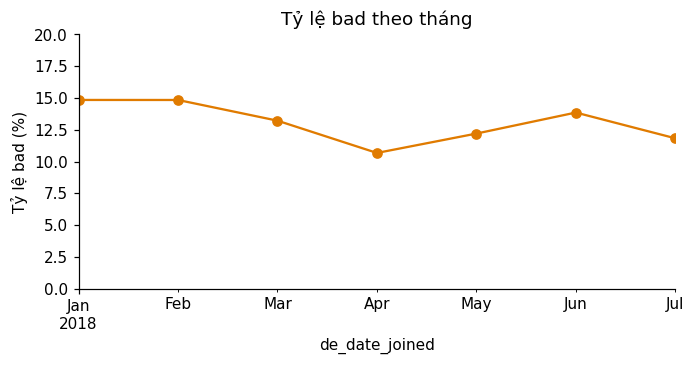

In [5]:
joined = pd.to_datetime(raw["de_date_joined"], format="%d/%m/%Y %H:%M")
by_month = raw.groupby(joined.dt.to_period("M"))["flag_bad"].agg(["size", "mean"])
by_month.columns = ["số hồ sơ", "tỷ lệ bad"]
display(by_month.round(3))

ax = by_month["tỷ lệ bad"].mul(100).plot(marker="o", figsize=(7, 3), color="#E07B00")
ax.set_ylim(0, 20); ax.set_ylabel("Tỷ lệ bad (%)"); ax.set_title("Tỷ lệ bad theo tháng")
plt.show()

Dữ liệu trải từ **tháng 1 đến tháng 7/2018**, tỷ lệ bad dao động 11–15%. Dữ liệu có thứ tự thời gian, nên khi kiểm tra mô hình cần dùng **các tháng sau** (xem bước 3).

Mã quốc gia gần như toàn bộ là `id`, nên đây nhiều khả năng là dữ liệu của một app cho vay ở Indonesia.

### 1.3 Tỷ lệ bad theo một vài biến khai báo

In [6]:
for col in ["de_education", "de_employment_type", "de_marital_status"]:
    t = raw.groupby(col)["flag_bad"].agg(["size", "mean"]).rename(columns={"size": "số hồ sơ", "mean": "tỷ lệ bad"})
    print("\n" + col)
    display(t.round(3))


de_education


,số hồ sơ,tỷ lệ bad
de_education,,
1,856,0.169
2,24589,0.146
3,5758,0.116
4,8258,0.099
5,1561,0.060



de_employment_type


,số hồ sơ,tỷ lệ bad
de_employment_type,,
1,29566,0.118
2,6621,0.157
3,4833,0.161
4,2,0.500



de_marital_status


,số hồ sơ,tỷ lệ bad
de_marital_status,,
1,20154,0.130
2,20020,0.126
3,500,0.196
4,348,0.256


Học vấn càng cao thì tỷ lệ bad càng thấp. Một số nhóm rất nhỏ (`de_employment_type = 4` chỉ có 2 hồ sơ, hôn nhân 3–4 vài trăm hồ sơ), cần gộp lại để tỷ lệ ổn định.

## 2. Làm sạch và tạo biến

Máy không hiểu được một danh sách 40 tên app hay một chuỗi JSON. Ta tóm tắt chúng thành con số có ý nghĩa.

| Dữ liệu gốc | Biến mới | Lý do |
|---|---|---|
| `ph_app_list` | số app vay, số app ngân hàng, số app game, tổng số app | Người đang cài nhiều app vay có thể đang vay nhiều nơi |
| `ph_call_log_stats` | tổng cuộc gọi, % gọi đến/đi ngày/đêm, tổng thời lượng | Mức độ hoạt động xã hội |
| `ph_other_device_info` | hãng điện thoại | Có thể phản ánh thu nhập |
| `fb_dob`, `fb_gender` | tuổi FB lệch tuổi khai báo, giới tính FB có khớp không | Dấu hiệu khai gian |
| `fb_last_updated_date` | số ngày từ lần cập nhật FB đến lúc nộp đơn | Tài khoản còn hoạt động không |
| `de_date_joined` | tháng (để chia tập), giờ, ngày trong tuần | Hành vi nộp đơn |

Chỉ dùng thông tin có tại lúc nộp đơn.

In [7]:
# Từ khóa nhận diện app (tiếng Anh + tiếng Indonesia)
LOAN_KEYWORDS = ("pinjam", "kredit", "loan", "cash", "dana", "uang", "rupiah", "credit",
                 "akulaku", "silvrr", "tunaiku", "modal", "kta", "paylater")
BANK_KEYWORDS = ("bca", "bni", "mandiri", "bri", "cimb", "danamon", "permata", "btn", "jenius")
GAME_KEYWORDS = ("game", "legends", "pubg", "freefire", "dts.freefire", "clash")
# Kredivo có trên ~98% máy, nhiều khả năng là chính app cho vay, nên không đếm
IGNORE_APPS = {"com.finaccel.android"}

apps = raw["ph_app_list"].apply(ast.literal_eval)
share = pd.Series([a for l in apps for a in set(l)]).value_counts() / len(raw)
print("App phổ biến nhất:\n", share.head(5).round(3))

App phổ biến nhất:
 com.finaccel.android                         0.978
com.whatsapp                                 0.946
com.instagram.android                        0.744
com.google.android.instantapps.supervisor    0.726
com.grabtaxi.passenger                       0.614
Name: count, dtype: float64


In [8]:
def count_keywords(app_list, keywords):
    return sum(1 for a in app_list if a not in IGNORE_APPS and any(k in a.lower() for k in keywords))

def relation_group(x):
    if pd.isna(x):
        return "Not declared"
    x = str(x)
    if x.startswith("Married"):
        return "Married"
    if x.startswith("Single"):
        return "Single"
    if x.startswith("In a relationship") or x.startswith("Engaged"):
        return "In a relationship / engaged"
    return "Other"

d = raw
df = pd.DataFrame({"flag_bad": d["flag_bad"]})

# Thời điểm nộp đơn
df["month"] = joined.dt.to_period("M").astype(str)
df["apply_hour"] = joined.dt.hour
df["apply_weekday"] = np.where(joined.dt.dayofweek >= 5, "Weekend", "Weekday")

# Nhân khẩu học
df["age"] = d["de_age"]
df["gender"] = d["de_gender"].map({1: "Male", 2: "Female"})
df["num_friends"] = d["de_num_friends"].replace(-1, np.nan)               # -1 = không có dữ liệu
df["log_salary"] = np.log1p(d["de_monthly_salary"].replace(0, np.nan))    # lương lệch phải → log
df["employment_type"] = d["de_employment_type"].map(
    {1: "Full-time", 2: "Part-time", 3: "Business owner", 4: "Full-time"})   # 4: không có trong đề, 2 hồ sơ
df["employment_duration"] = d["de_employment_duration"]
df["education"] = d["de_education"]
df["marital_status"] = d["de_marital_status"].map(
    {1: "Single", 2: "Married", 3: "Divorced / widowed", 4: "Divorced / widowed"})
df["children"] = d["de_children"]

# Điện thoại
df["total_contacts"] = d["ph_total_contacts"]
df["contacts_zero"] = np.where(d["ph_total_contacts"] == 0, "Yes", "No")
brand = d["ph_other_device_info"].apply(lambda s: json.loads(s).get("brand", "unknown")).str.lower()
df["device_brand"] = brand.where(brand.isin(brand.value_counts().index[:8]), "other")

calls = pd.DataFrame(d["ph_call_log_stats"].apply(lambda s: json.loads(s) if isinstance(s, str) else {}).tolist())
df["call_total"] = calls["total_calls"]
df["call_pct_in_day"] = calls["percent_incoming_daytime"]
df["call_pct_in_night"] = calls["percent_incoming_nighttime"]
df["call_pct_out_day"] = calls["percent_outgoing_daytime"]
df["call_pct_out_night"] = calls["percent_outgoing_nighttime"]
df["call_pct_other"] = calls["percent_other_calls"]
dur_cols = [c for c in calls.columns if c.startswith("duration")]
df["call_dur_total_log"] = np.log1p(calls[dur_cols].sum(axis=1, min_count=1))

df["n_apps"] = apps.str.len()
df["n_loan_apps"] = apps.apply(lambda a: count_keywords(a, LOAN_KEYWORDS))
df["n_bank_apps"] = apps.apply(lambda a: count_keywords(a, BANK_KEYWORDS))
df["n_game_apps"] = apps.apply(lambda a: count_keywords(a, GAME_KEYWORDS))

# Facebook: kiểm tra tính nhất quán với thông tin khai báo
df["has_fb"] = np.where(d["fb_gender"].notna() | d["fb_last_updated_date"].notna(), "Yes", "No")
fb_gender = d["fb_gender"].map({"male": 1, "female": 2})
df["fb_gender_mismatch"] = np.select([fb_gender.isna(), fb_gender != d["de_gender"]], ["No FB", "Mismatch"], "Match")
fb_age = (joined - pd.to_datetime(d["fb_dob"], format="%m/%d/%Y", errors="coerce")).dt.days / 365.25
df["fb_age_gap"] = (fb_age - d["de_age"]).abs()
fb_upd = pd.to_datetime(d["fb_last_updated_date"], utc=True, errors="coerce").dt.tz_localize(None)
df["fb_days_since_update"] = (joined - fb_upd).dt.days.clip(lower=0)   # 0,2% cập nhật sau ngày nộp đơn → đặt về 0
df["fb_relation_group"] = d["fb_relation"].apply(relation_group)

NUMERIC = ["age", "num_friends", "log_salary", "employment_duration", "children", "education",
           "apply_hour", "total_contacts", "n_apps", "n_loan_apps", "n_bank_apps", "n_game_apps",
           "call_total", "call_pct_in_day", "call_pct_in_night", "call_pct_out_day", "call_pct_out_night",
           "call_pct_other", "call_dur_total_log", "fb_age_gap", "fb_days_since_update"]
CATEGORICAL = ["gender", "employment_type", "marital_status", "apply_weekday", "device_brand",
               "fb_relation_group", "fb_gender_mismatch", "has_fb", "contacts_zero"]
print("Số biến:", len(NUMERIC) + len(CATEGORICAL))
df.head()

.venv/lib/python3.9/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


Số biến: 30


,flag_bad,month,apply_hour,apply_weekday,age,gender,num_friends,log_salary,employment_type,employment_duration,education,marital_status,children,total_contacts,contacts_zero,device_brand,call_total,call_pct_in_day,call_pct_in_night,call_pct_out_day,call_pct_out_night,call_pct_other,call_dur_total_log,n_apps,n_loan_apps,n_bank_apps,n_game_apps,has_fb,fb_gender_mismatch,fb_age_gap,fb_days_since_update,fb_relation_group
0,0,2018-04,14,Weekend,26,Male,2535.0,14.914123,Full-time,51,2,Married,0,66,No,xiaomi,109.0,3.67,1.83,28.44,63.30,2.75,10.714662,54,0,0,4,Yes,Match,0.373717,108.0,Married
1,0,2018-01,17,Weekday,22,Male,685.0,15.201805,Full-time,28,4,Single,0,69,No,oppo,2.0,0.00,0.00,100.00,0.00,0.00,0.000000,51,0,0,1,Yes,Match,0.951403,37.0,Not declared
2,1,2018-01,16,Weekday,32,Male,1765.0,15.761421,Full-time,35,4,Married,2,315,No,oppo,376.0,13.56,6.65,41.76,24.73,13.30,9.646011,47,1,1,3,Yes,Match,0.219028,8.0,Married
3,0,2018-01,22,Weekday,31,Female,407.0,16.811243,Business owner,37,3,Married,2,84,No,oppo,0.0,0.00,0.00,0.00,0.00,0.00,0.000000,42,3,1,0,Yes,Match,0.441478,30.0,Married
4,0,2018-01,18,Weekday,27,Male,3064.0,14.914123,Full-time,36,3,Single,0,0,Yes,vivo,15.0,0.00,0.00,46.67,53.33,0.00,4.595120,17,0,0,0,Yes,Match,0.496235,30.0,In a relationship / engaged


**Quyết định ở bước 2:**
- Bỏ `de_accomodation_type` và `ph_country_code`: gần như chỉ có một giá trị.
- `de_num_friends = -1` và lương = 0 được coi là thiếu dữ liệu.
- Gộp các nhóm quá nhỏ: hôn nhân 3–4 (vài trăm hồ sơ) gộp thành "Divorced / widowed". Mã công việc 4 không có trong mô tả của đề và chỉ có 2 hồ sơ, nên không xác định được ý nghĩa; gộp vào nhóm đông nhất (Full-time, 72% hồ sơ) thay vì để thành nhóm riêng.
- Không đếm app Kredivo khi đếm app vay.

## 3. Chia dữ liệu: training, validation và test set

| Tập | Dữ liệu | Dùng để |
|---|---|---|
| **Training set** | 75% hồ sơ tháng 1–5 | Huấn luyện mô hình |
| **Validation set** | 25% hồ sơ tháng 1–5 | So sánh, phát hiện overfitting trong lúc xây mô hình |
| **Test set (out-of-time)** | Toàn bộ hồ sơ tháng 6–7 | Đánh giá cuối cùng trên dữ liệu mô hình chưa từng thấy |

**Vì sao test set là 2 tháng cuối thay vì chia ngẫu nhiên?** Khi đem dùng thật, mô hình luôn chấm cho khách hàng *trong tương lai*. Test trên các tháng sau mô phỏng đúng tình huống đó, và phát hiện được nếu hành vi khách hàng thay đổi theo thời gian. Basel khuyến nghị kiểm tra khả năng phân biệt trên dữ liệu không dùng lúc xây mô hình [3, tr. 36]; chia theo thời gian còn chặt chẽ hơn vì dữ liệu kiểm tra thuộc giai đoạn sau.

In [9]:
OOT_MONTHS = ["2018-06", "2018-07"]
is_oot = df["month"].isin(OOT_MONTHS)
dev, test = df[~is_oot], df[is_oot]
train, valid = train_test_split(dev, test_size=0.25, stratify=dev["flag_bad"], random_state=SEED)
sets = {"Train": train, "Validation": valid, "Test OOT": test}

pd.DataFrame({k: {"số hồ sơ": len(v), "tỷ lệ bad": "{:.1%}".format(v["flag_bad"].mean())} for k, v in sets.items()}).T

,số hồ sơ,tỷ lệ bad
Train,23831,12.9%
Validation,7944,12.9%
Test OOT,9247,13.2%


**Quyết định:** test set chỉ dùng **một lần ở cuối**, không dùng để chọn biến hay chỉnh tham số.

## 4. Chọn biến bằng WOE và IV

**Ý tưởng:** chia mỗi biến thành vài nhóm, xem **tỷ lệ bad của từng nhóm**. Các nhóm càng khác nhau thì biến càng có ích.

- **WOE** (Weight of Evidence) = ln(%good trong nhóm / %bad trong nhóm): "điểm rủi ro" của nhóm. Dương là an toàn hơn trung bình, âm là rủi ro hơn.
- **IV** (Information Value) = Σ (%good − %bad) × WOE: sức dự báo của cả biến. Cách đọc IV xem ở mục 4.3.

Các nhóm và WOE chỉ được **học trên tập train**, rồi áp nguyên cho validation và test.

WOE và IV là công cụ chuẩn khi xây scorecard tín dụng [1][2].

In [10]:
MISSING = "Missing"

def numeric_edges(x, max_bins=6, min_share=0.05):
    # Chia theo phân vị, rồi gộp nhóm nhỏ (< 5% hồ sơ) vào nhóm bên cạnh
    qs = np.unique(np.nanquantile(x, np.linspace(0, 1, max_bins + 1)))
    edges = [-np.inf] + list(qs[:-1]) + [np.inf]
    while len(edges) > 3:
        counts = pd.cut(x, edges, include_lowest=True).value_counts(sort=False, normalize=True).to_numpy()
        i = int(np.argmin(counts))
        if counts[i] >= min_share:
            break
        del edges[i if i > 0 else 1]
    return edges

def to_bins(x, spec):
    if spec["kind"] == "numeric":
        lab = pd.cut(x, spec["edges"], include_lowest=True).astype(str)
        return lab.where(x.notna(), MISSING)
    lab = x.astype(object).where(x.notna(), MISSING).astype(str)
    return lab.where(lab.isin(spec["keep"]), "Other")

def woe_table(lab, y):
    t = pd.DataFrame({"bin": lab, "y": y}).groupby("bin")["y"].agg(n="size", bad="sum")
    t["good"] = t["n"] - t["bad"]
    t["pct_good"] = (t["good"] + 0.5) / (t["good"].sum() + 0.5)   # +0,5 tránh chia cho 0
    t["pct_bad"] = (t["bad"] + 0.5) / (t["bad"].sum() + 0.5)
    t["bad_rate"] = t["bad"] / t["n"]
    t["woe"] = np.log(t["pct_good"] / t["pct_bad"])
    t["iv_part"] = (t["pct_good"] - t["pct_bad"]) * t["woe"]
    return t

def fit_binning(x, y, kind):
    if kind == "numeric":
        spec = {"kind": kind, "edges": numeric_edges(x)}
    else:
        share = x.astype(object).where(x.notna(), MISSING).value_counts(normalize=True)
        spec = {"kind": kind, "keep": set(share[share >= 0.05].index.astype(str))}
    t = woe_table(to_bins(x, spec), y)
    if kind == "numeric":   # sắp nhóm theo thứ tự giá trị
        order = [str(iv) for iv in pd.IntervalIndex.from_breaks(spec["edges"], closed="right")]
        t = t.reindex([o for o in order if o in t.index] + [i for i in t.index if i not in order])
    spec.update(table=t, woe=t["woe"].to_dict(), iv=float(t["iv_part"].sum()))
    return spec

def woe_transform(frame, specs, cols):
    return pd.DataFrame({c: to_bins(frame[c], specs[c]).map(specs[c]["woe"]).fillna(0.0) for c in cols}, index=frame.index)

specs = {c: fit_binning(train[c], train["flag_bad"], "numeric") for c in NUMERIC}
specs.update({c: fit_binning(train[c], train["flag_bad"], "categorical") for c in CATEGORICAL})

### 4.1 Ví dụ: biến "số app vay trong máy"

In [11]:
specs["n_loan_apps"]["table"][["n", "bad", "bad_rate", "woe"]].round(3)

,n,bad,bad_rate,woe
bin,,,,
"(-inf, 0.0]",9594,827,0.086,0.450
"(0.0, 1.0]",8031,878,0.109,0.187
"(1.0, 2.0]",2889,408,0.141,-0.106
"(2.0, inf]",3317,960,0.289,-1.012


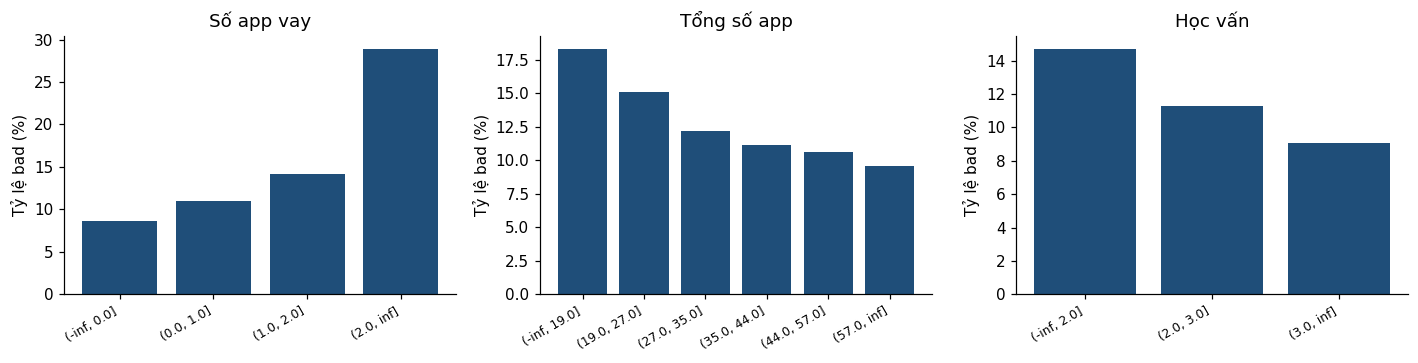

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c, name in zip(axes, ["n_loan_apps", "n_apps", "education"], ["Số app vay", "Tổng số app", "Học vấn"]):
    t = specs[c]["table"]
    ax.bar(range(len(t)), t["bad_rate"] * 100, color="#1F4E79")
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.index, rotation=30, ha="right", fontsize=8)
    ax.set_title(name); ax.set_ylabel("Tỷ lệ bad (%)")
plt.tight_layout(); plt.show()

Người không có app vay có tỷ lệ bad khoảng 9%, còn người có từ 3 app vay trở lên khoảng 29%, cao gấp hơn 3 lần. Điều này có thể giải thích là người vay nhiều nơi thì đang có khả năng tài chính yếu hơn, và cũng phải trả nhiều khoản vay khác nhau hơn nên dễ mất khả năng trả nợ, tỉ lệ bad cũng cao hơn. Ít app cũng rủi ro hơn, vì có thể là máy mới và ứng dụng vay được cài vội để vay gấp. Học vấn cao thì rủi ro thấp hơn.

### 4.2 Thay giá trị gốc bằng WOE

Sau khi có bảng WOE của từng biến, **mỗi khách được thay giá trị gốc bằng WOE của nhóm mà họ rơi vào**, làm với từng biến. Ví dụ 5 khách trong training set:

In [13]:
example_cols = ["n_loan_apps", "n_apps", "education"]
sample = train.sample(5, random_state=1)
x_example = woe_transform(sample, specs, example_cols)

show = pd.DataFrame(index=sample.index)
for c in example_cols:
    show[(c, "giá trị gốc")] = sample[c]
    show[(c, "nhóm")] = to_bins(sample[c], specs[c])
    show[(c, "WOE")] = x_example[c].round(2)
show.columns = pd.MultiIndex.from_tuples(show.columns)
show

n_loan_apps                         n_apps                       education                   
      giá trị gốc         nhóm   WOE giá trị gốc          nhóm   WOE giá trị gốc         nhóm   WOE
32981           0  (-inf, 0.0]  0.45          12  (-inf, 19.0] -0.42           4   (3.0, inf]  0.39
14482           0  (-inf, 0.0]  0.45          41  (35.0, 44.0]  0.17           2  (-inf, 2.0] -0.16
27115           0  (-inf, 0.0]  0.45          39  (35.0, 44.0]  0.17           4   (3.0, inf]  0.39
28444           2   (1.0, 2.0] -0.11          19  (-inf, 19.0] -0.42           2  (-inf, 2.0] -0.16
2372            0  (-inf, 0.0]  0.45          44  (35.0, 44.0]  0.17           4   (3.0, inf]  0.39

**Cách đọc:** khách có 0 app vay rơi vào nhóm `(-inf, 0.0]`, nên nhận WOE +0,45 (nhóm an toàn). Cùng khách đó có thể rơi vào nhóm rủi ro của biến khác, ví dụ ít app nói chung (WOE âm).

Sau bước này, **mỗi biến trở thành một cột số WOE**, mỗi khách một số. Bảng số này là:
- dữ liệu dùng để tính **tương quan** ở quy tắc 2 (tương quan giữa hai cột WOE),
- dữ liệu đưa vào **Logistic Regression** ở bước 5.

### 4.3 Chọn biến

**Quy tắc 1: bỏ biến có IV < 0,02.** Cách đọc IV theo Siddiqi (2006) [1], trích lại trong Delamaire (2012, tr. 152) [2]: < 0,02 không có ích, 0,02–0,1 yếu, 0,1–0,3 trung bình, > 0,3 mạnh. Ngưỡng 0,5 là quy ước kinh nghiệm thường dùng thêm:

| IV | Ý nghĩa |
|---|---|
| < 0,02 | Không có ích |
| 0,02 – 0,1 | Yếu |
| 0,1 – 0,3 | Trung bình |
| 0,3 – 0,5 | Mạnh |
| > 0,5 | Mạnh đáng ngờ: cần kiểm tra lại (quy ước kinh nghiệm) |

IV > 0,5 đáng ngờ vì hiếm có biến nào lúc nộp đơn một mình tách good/bad rõ đến vậy. Hai nguyên nhân thường gặp:
- **Rò rỉ dữ liệu (data leakage):** biến chứa thông tin chỉ có *sau* khi biết kết quả [9], ví dụ số ngày quá hạn. Trong bài, 0,2% hồ sơ có ngày cập nhật Facebook sau ngày nộp đơn, nên đã được đặt về 0 (bước 2).
- **Nhóm quá nhỏ:** WOE của nhóm có vài hồ sơ rất cực đoan do tình cờ, làm IV bị thổi phồng trên train nhưng không lặp lại trên test (overfitting). Bài gộp các nhóm dưới 5% hồ sơ để tránh việc này.

**Quy tắc 2: bỏ biến tương quan > 0,6 (trên WOE) với một biến đã chọn có IV cao hơn.**
Hai biến tương quan cao gần như nói cùng một điều. Giữ cả hai không thêm thông tin, mà còn làm hệ số hồi quy **không ổn định**: mô hình không biết nên "chia công" cho biến nào, nên hệ số có thể dao động mạnh, thậm chí đổi dấu. Hiện tượng này gọi là đa cộng tuyến (collinearity) [4, mục 3.3.3]. Giữ biến có IV cao hơn vì nó mang nhiều thông tin hơn.

**Quy tắc 3: bỏ biến có hệ số logistic ngược dấu.**
Vì WOE cao = an toàn, hệ số của mọi biến phải **âm** (WOE cao → PD thấp). Hệ số dương nghĩa là mô hình chấm nhóm an toàn thành rủi ro hơn: trái với chính dữ liệu của biến đó, không hợp lý về nghiệp vụ và không giải thích được cho khách. Scorecard cần quan hệ đi đúng chiều và giải thích được: Siddiqi (2006) yêu cầu dấu của biến phải đúng logic nghiệp vụ, trích lại trong Delamaire (2012, tr. 152) [1][2].

In [14]:
x_woe = {k: woe_transform(v, specs, NUMERIC + CATEGORICAL) for k, v in sets.items()}
iv = pd.Series({c: s["iv"] for c, s in specs.items()}).sort_values(ascending=False)
corr = x_woe["Train"].corr().abs()

decision, selected = {}, []
for c in iv.index:
    if iv[c] < 0.02:
        decision[c] = "Loại: IV < 0,02"
    elif any(corr.loc[c, k] > 0.6 for k in selected):
        decision[c] = "Loại: tương quan cao"
    else:
        selected.append(c); decision[c] = "Giữ"

iv_log = pd.DataFrame({"IV": iv.round(4), "Quyết định": pd.Series(decision)})
iv_log

,IV,Quyết định
n_loan_apps,0.2827,Giữ
n_bank_apps,0.0788,Giữ
n_apps,0.0692,Giữ
education,0.0507,Giữ
call_pct_in_day,0.0505,Giữ
call_pct_other,0.0400,Giữ
call_total,0.0398,Giữ
fb_age_gap,0.0391,Giữ
employment_duration,0.0378,Giữ
employment_type,0.0288,Giữ


In [15]:
# Quy tắc 2: các cặp biến có tương quan WOE > 0,6 trên training set
corr_all = x_woe["Train"].corr().abs()
pairs = [(a, b, corr_all.loc[a, b]) for k, a in enumerate(corr_all.index)
         for b in corr_all.index[k + 1:] if corr_all.loc[a, b] > 0.6]
sel_corr = corr_all.loc[selected, selected].where(~np.eye(len(selected), dtype=bool))
print("Tương quan cao nhất giữa các biến đã qua quy tắc 1:", round(sel_corr.max().max(), 2))
pd.DataFrame([{"Biến 1": a, "Biến 2": b, "Tương quan": round(v, 2),
               "Quyết định biến 1": decision[a], "Quyết định biến 2": decision[b]} for a, b, v in pairs])

Tương quan cao nhất giữa các biến đã qua quy tắc 1: 0.56


,Biến 1,Biến 2,Tương quan,Quyết định biến 1,Quyết định biến 2
0,total_contacts,contacts_zero,0.76,"Loại: IV < 0,02","Loại: IV < 0,02"
1,call_pct_in_night,call_pct_out_day,0.64,"Loại: IV < 0,02","Loại: IV < 0,02"
2,call_pct_in_night,call_dur_total_log,0.68,"Loại: IV < 0,02",Giữ
3,call_pct_out_day,call_pct_other,0.65,"Loại: IV < 0,02",Giữ
4,call_pct_out_day,call_dur_total_log,0.66,"Loại: IV < 0,02",Giữ


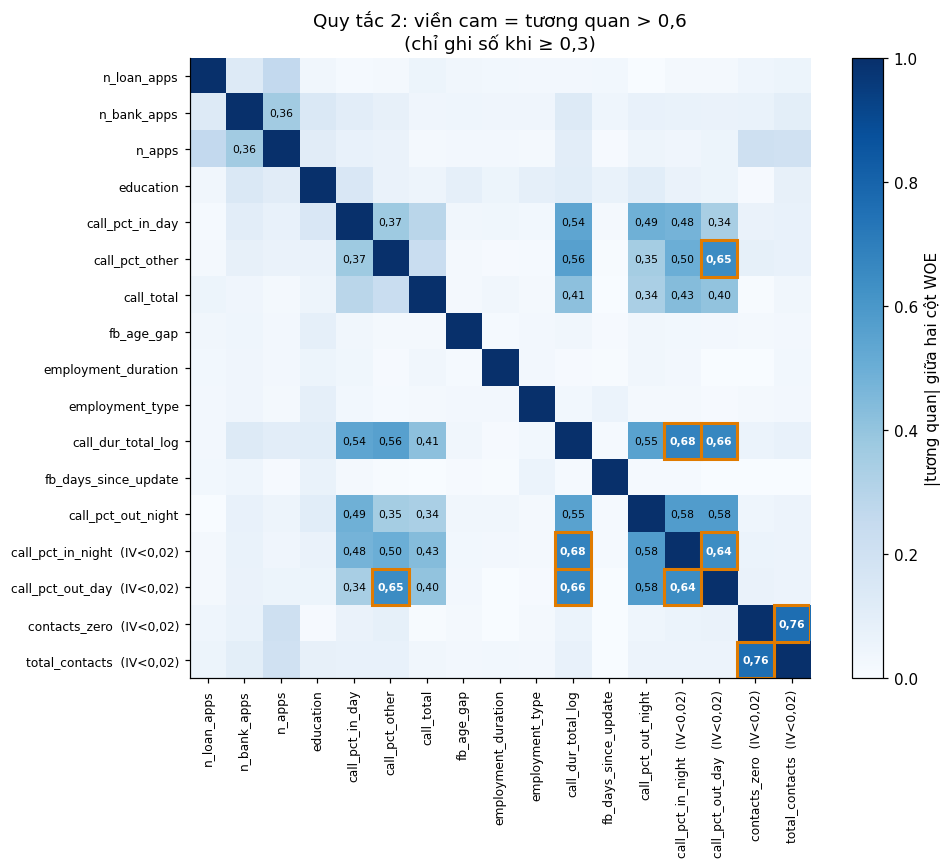

In [16]:
# Hình: tương quan giữa các cột WOE (biến qua quy tắc 1 + các biến nằm trong cặp > 0,6)
show_vars = [c for c in iv.index if iv[c] >= 0.02] + sorted({v for a, b, _ in pairs for v in (a, b) if iv[v] < 0.02})
m = corr_all.loc[show_vars, show_vars]
names = [f"{v}  (IV<0,02)" if iv[v] < 0.02 else v for v in show_vars]

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=90, fontsize=8)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
for r_ in range(len(names)):
    for c_ in range(len(names)):
        v = m.iloc[r_, c_]
        if r_ != c_ and v >= 0.3:
            ax.text(c_, r_, f"{v:.2f}".replace(".", ","), ha="center", va="center", fontsize=7,
                    color="white" if v > 0.6 else "black", fontweight="bold" if v > 0.6 else "normal")
        if r_ != c_ and v > 0.6:
            ax.add_patch(plt.Rectangle((c_ - 0.5, r_ - 0.5), 1, 1, fill=False, edgecolor="#E07B00", lw=2))
plt.colorbar(im, ax=ax, fraction=0.04, label="|tương quan| giữa hai cột WOE")
ax.set_title("Quy tắc 2: viền cam = tương quan > 0,6\n(chỉ ghi số khi ≥ 0,3)")
plt.tight_layout(); plt.show()

Các cặp tương quan trên 0,6 đều có ít nhất một biến đã bị loại ở quy tắc 1 (IV < 0,02). Trong các biến còn lại, tương quan cao nhất chỉ khoảng 0,56, nên **quy tắc 2 không phải loại thêm biến nào**. Quy tắc này vẫn giữ lại như một lớp bảo vệ.

Ví dụ, với tổng thời lượng gọi: phần lớn thông tin của nó (người hay gọi điện là người có đời sống xã hội ổn định) đã được các biến cuộc gọi khác nói rồi. Phần riêng còn lại rất nhỏ, gần như là nhiễu, và tình cờ nghiêng về hướng ngược lại. Kết quả là hệ số ra dương.

## 5. Hai mô hình

**Logistic Regression: cộng điểm rồi đổi thành xác suất.** Mỗi biến được nhân với một hệ số rồi cộng lại thành một tổng *z*. Tổng này được đưa qua hàm logistic, PD = 1 / (1 + e<sup>−z</sup>), để luôn ra một số từ 0 đến 1. Hệ số được chọn sao cho PD dự báo khớp nhất với dữ liệu good/bad đã biết. Vì mô hình chỉ là một phép cộng, có thể đổi thẳng mỗi nhóm của mỗi biến thành một số điểm (scorecard) [1]. Hệ số được ước lượng bằng maximum likelihood [4, chương 4].

**Gradient Boosting: nhiều cây nhỏ, cây sau sửa lỗi cây trước.** Cây quyết định thứ nhất đưa ra dự đoán thô. Cây thứ hai học **phần sai** của cây thứ nhất, cây thứ ba học phần sai còn lại, cứ thế hàng trăm cây. Mỗi cây chỉ đóng góp một phần nhỏ (learning rate 0,05) để mô hình học từ từ, không học thuộc. "Gradient" nghĩa là mỗi cây đi theo hướng làm sai số giảm nhanh nhất (steepest descent) [5, mục 10.10][6]. Bài dùng `HistGradientBoostingClassifier` của scikit-learn: chia giá trị mỗi biến thành các khoảng (histogram) để chạy nhanh, theo ý tưởng của LightGBM [7].


| | Logistic Regression trên WOE (scorecard) | Gradient Boosting |
|---|---|---|
| Hình dung | **Bảng cộng điểm**: mỗi đặc điểm cộng/trừ một số điểm | **Hội đồng hàng trăm người chấm nhỏ** (cây quyết định), người sau sửa lỗi người trước |
| Ưu điểm | Dễ giải thích, chuẩn ngành ngân hàng, ổn định | Bắt được quan hệ phi tuyến và tương tác giữa biến |
| Nhược điểm | Bỏ lỡ tương tác giữa biến | Khó giải thích hơn, dễ overfitting |

Logistic là mô hình nền dễ giải thích; Boosting là mô hình thách thức, để xem độ phức tạp thêm vào có đáng không. Một nghiên cứu so sánh nhiều thuật toán trên 8 bộ dữ liệu tín dụng cho thấy nhiều thuật toán, nhất là các mô hình tổ hợp (ensemble), dự báo chính xác hơn logistic regression, vốn được coi là chuẩn của ngành [10]. Logistic vẫn phổ biến trong ngân hàng vì dễ giải thích.

### 5.1 Logistic Regression (scorecard)

Với WOE = ln(%good / %bad), hệ số hợp lý phải **âm** (nhóm an toàn hơn thì xác suất bad thấp hơn). Biến nào ra hệ số dương (thường do trùng thông tin với biến khác) thì loại rồi chạy lại.

In [17]:
cols = list(selected)
while True:
    lr = LogisticRegression(C=1.0, max_iter=2000).fit(x_woe["Train"][cols], train["flag_bad"])
    coef = pd.Series(lr.coef_[0], index=cols)
    if (coef <= 0).all():
        break
    worst = coef.idxmax()
    print("Loại vì hệ số ngược dấu:", worst)
    iv_log.loc[worst, "Quyết định"] = "Loại: hệ số ngược dấu"
    cols.remove(worst)

lr_cols = cols
print("\nBiến cuối cùng ({}):".format(len(lr_cols)))
coef.round(3).sort_values()

Loại vì hệ số ngược dấu: call_dur_total_log
Loại vì hệ số ngược dấu: call_pct_out_night

Biến cuối cùng (11):


n_apps                 -1.439
n_loan_apps            -1.312
employment_duration    -1.051
employment_type        -0.951
call_total             -0.842
n_bank_apps            -0.795
fb_age_gap             -0.780
fb_days_since_update   -0.749
call_pct_other         -0.488
call_pct_in_day        -0.474
education              -0.468
dtype: float64

In [18]:
# Quy tắc 3: vì sao hệ số bị ngược dấu? So sánh hệ số khi biến đứng một mình và khi nằm trong mô hình
rows = []
for c in iv_log.index[iv_log["Quyết định"] == "Loại: hệ số ngược dấu"]:
    solo = LogisticRegression(max_iter=2000).fit(x_woe["Train"][[c]], train["flag_bad"]).coef_[0][0]
    full = LogisticRegression(C=1.0, max_iter=2000).fit(x_woe["Train"][lr_cols + [c]], train["flag_bad"])
    top = x_woe["Train"][lr_cols].corrwith(x_woe["Train"][c]).abs().sort_values(ascending=False).head(2)
    rows.append({"Biến": c, "Hệ số khi đứng một mình": round(solo, 3),
                 "Hệ số trong mô hình": round(pd.Series(full.coef_[0], index=lr_cols + [c])[c], 3),
                 "Tương quan cao nhất với biến đã giữ": ", ".join(f"{k} ({v:.2f})" for k, v in top.items())})
pd.DataFrame(rows)

,Biến,Hệ số khi đứng một mình,Hệ số trong mô hình,Tương quan cao nhất với biến đã giữ
0,call_dur_total_log,-0.988,0.555,"call_pct_other (0.56), call_pct_in_day (0.54)"
1,call_pct_out_night,-0.987,0.017,"call_pct_in_day (0.49), call_pct_other (0.35)"


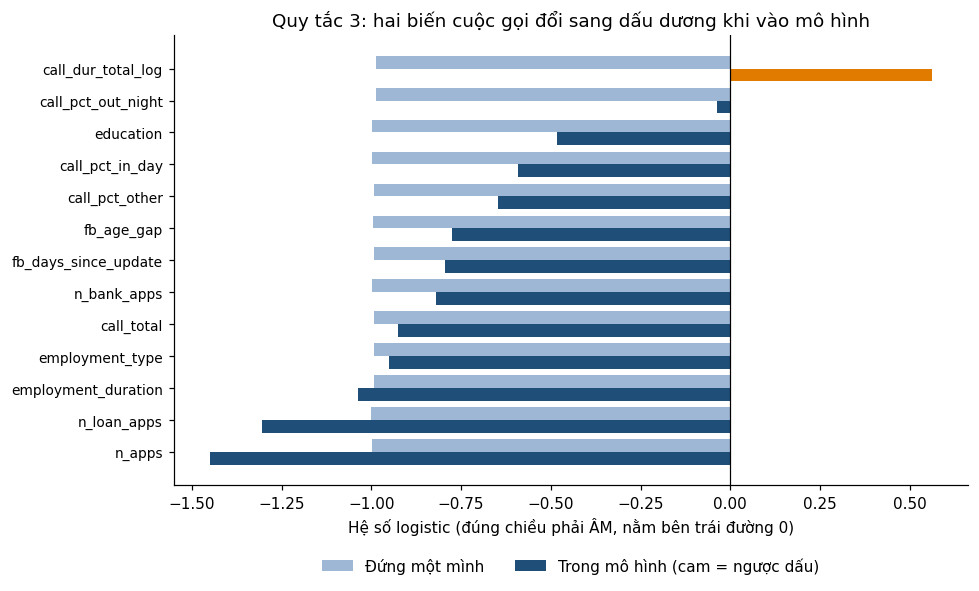

In [19]:
# Hình: hệ số khi đứng một mình vs khi vào mô hình (vòng 1, đủ 13 biến đã qua quy tắc 1 và 2)
y_tr = train["flag_bad"]
solo = pd.Series({c: LogisticRegression(max_iter=2000).fit(x_woe["Train"][[c]], y_tr).coef_[0][0] for c in selected})
together = pd.Series(LogisticRegression(C=1.0, max_iter=2000).fit(x_woe["Train"][selected], y_tr).coef_[0], index=selected)
order = together.sort_values().index

fig, ax = plt.subplots(figsize=(9, 5.5))
pos = np.arange(len(order))
ax.barh(pos + 0.2, solo[order], height=0.4, color="#9db7d5", label="Đứng một mình")
ax.barh(pos - 0.2, together[order], height=0.4, color=["#E07B00" if v > 0 else "#1F4E79" for v in together[order]],
        label="Trong mô hình (cam = ngược dấu)")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(pos); ax.set_yticklabels(order, fontsize=9)
ax.set_xlabel("Hệ số logistic (đúng chiều phải ÂM, nằm bên trái đường 0)")
ax.set_title("Quy tắc 3: hai biến cuộc gọi đổi sang dấu dương khi vào mô hình")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False); plt.tight_layout(); plt.show()

**Nhận xét:** khi đứng một mình, **mọi biến đều có hệ số âm** (đúng chiều), và đều xấp xỉ **−1**. Đây là tính chất của WOE: WOE đã là log-odds của nhóm, nên logistic regression trên **một** cột WOE luôn cho hệ số khoảng −1. Khi vào mô hình cùng nhau, `call_dur_total_log` chuyển sang **dương** (cột cam). Loại biến này rồi chạy lại thì `call_pct_out_night` cũng chuyển sang dương (+0,02), nên bị loại ở vòng 2 (bảng phía trên). Mỗi biến chỉ tương quan khoảng 0,5 với từng biến đã giữ, chưa tới ngưỡng 0,6 của quy tắc 2, nhưng trùng thông tin với **nhiều biến cuộc gọi cùng lúc**.

**Vì sao hệ số thay đổi?** Trong mô hình nhiều biến, hệ số của một biến chỉ đo **phần thông tin riêng** của nó, tức phần mà các biến khác chưa giải thích. Với hồi quy tuyến tính, điều này được phát biểu chính xác bởi **định lý Frisch–Waugh–Lovell** [13][14]: hệ số của một biến bằng hệ số khi hồi quy theo **phần dư** của biến đó, sau khi đã trừ đi phần các biến khác giải thích được. Hồi quy logistic có tính chất tương tự (gần đúng). Biến thời lượng gọi trùng thông tin với các biến cuộc gọi khác, nên phần riêng còn lại chủ yếu là nhiễu, và hệ số bị đổi dấu.

**Minh họa bằng dữ liệu giả lập:** rủi ro chỉ phụ thuộc vào `x1`, còn `x2` là bản sao gần giống `x1` (tương quan 0,99). Lấy 4 mẫu dữ liệu khác nhau:

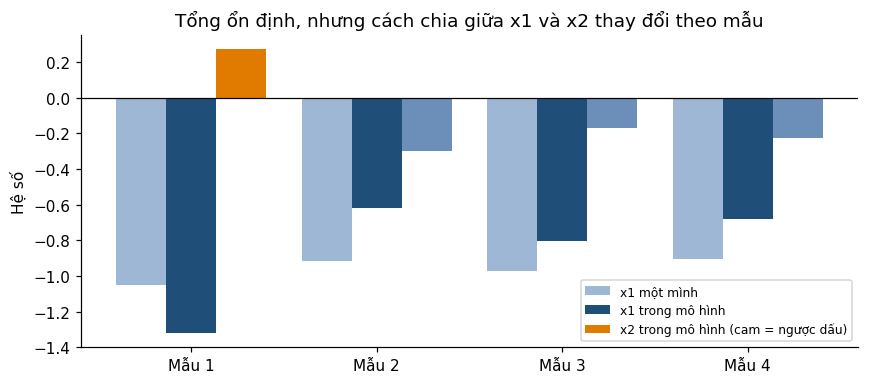

,x1 một mình,x1 trong mô hình,x2 trong mô hình,Tổng x1 + x2
Mẫu,,,,
Mẫu 1,-1.05,-1.32,0.27,-1.05
Mẫu 2,-0.92,-0.62,-0.30,-0.92
Mẫu 3,-0.97,-0.80,-0.17,-0.97
Mẫu 4,-0.91,-0.68,-0.22,-0.91


In [20]:
rows = []
for seed in range(4):
    rng = np.random.default_rng(seed); n = 3000
    x1 = rng.normal(size=n)
    x2 = x1 + rng.normal(scale=0.15, size=n)                    # gần như trùng x1
    y_sim = rng.random(n) < 1 / (1 + np.exp(2 + x1))             # rủi ro chỉ phụ thuộc x1
    both = LogisticRegression().fit(np.c_[x1, x2], y_sim).coef_[0]
    rows.append({"Mẫu": f"Mẫu {seed + 1}",
                 "x1 một mình": LogisticRegression().fit(x1[:, None], y_sim).coef_[0][0],
                 "x1 trong mô hình": both[0], "x2 trong mô hình": both[1], "Tổng x1 + x2": both.sum()})
sim = pd.DataFrame(rows).set_index("Mẫu")

fig, ax = plt.subplots(figsize=(8, 3.6))
pos = np.arange(len(sim))
ax.bar(pos - 0.27, sim["x1 một mình"], 0.27, color="#9db7d5", label="x1 một mình")
ax.bar(pos, sim["x1 trong mô hình"], 0.27, color="#1F4E79", label="x1 trong mô hình")
ax.bar(pos + 0.27, sim["x2 trong mô hình"], 0.27, color=["#E07B00" if v > 0 else "#6b8fb8" for v in sim["x2 trong mô hình"]],
       label="x2 trong mô hình (cam = ngược dấu)")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(pos); ax.set_xticklabels(sim.index); ax.set_ylabel("Hệ số")
ax.set_title("Tổng ổn định, nhưng cách chia giữa x1 và x2 thay đổi theo mẫu")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()
sim.round(2)

**Nhận xét:** cột **"Tổng x1 + x2"** luôn gần bằng hệ số của `x1` khi đứng một mình. Mô hình biết chắc hai biến *gộp lại* quan trọng đến mức nào. Nhưng **cách chia giữa x1 và x2 thay đổi theo từng mẫu**, vì chia kiểu nào thì dự báo cũng gần như nhau. Ở mẫu 1, `x2` còn bị **đổi sang dương** dù thực tế x2 không làm tăng rủi ro. Đây là hiện tượng đa cộng tuyến [4, mục 3.3.3], và là lý do bài loại các biến bị đổi dấu.

#### Logistic Regression tính PD như thế nào?

**Bắt đầu với 1 biến: số app vay.** Mô hình tính PD qua 2 bước:

**Bước 1: cộng điểm thành z**

$$z = \alpha + \beta \times \text{WOE}_{\text{số app vay}}$$

- **WOE** (đầu vào): WOE của nhóm mà khách rơi vào (mục 4.2). Số càng **cao** thì khách càng **an toàn**.
- **α** (alpha, hệ số chặn, *intercept*): điểm xuất phát, là mức rủi ro trung bình khi chưa biết gì về khách. Với WOE, α ≈ ln(số bad / số good) = ln(3.073 / 20.758) ≈ −1,91.
- **β** (beta, hệ số, *coefficient*): con số nhân với WOE, cho biết WOE đẩy z lên hay kéo xuống, và mạnh đến mức nào.
- **z** gọi là *log-odds*: z = ln(PD / (1 − PD)). z có thể là bất kỳ số nào, từ âm vô cùng đến dương vô cùng.

**Bước 2: đổi z thành xác suất bad**

$$PD = \frac{1}{1 + e^{-z}}$$

Hàm này (hàm logistic, hay *sigmoid*) ép mọi z vào khoảng 0 đến 1: z rất âm → PD gần 0, z = 0 → PD = 50%, z rất dương → PD gần 1.

**Vì sao β phải âm?** Đầu vào WOE cao = **an toàn**, nhưng đầu ra PD cao = **rủi ro**. Hai thứ đi **ngược chiều**, nên β phải âm. Khi đó WOE dương (an toàn) làm z giảm, PD giảm; WOE âm (rủi ro) làm z tăng, PD tăng.

**α và β được tính thế nào?** Máy thử dần các giá trị (phương pháp *maximum likelihood*) để tìm α, β làm PD dự báo khớp nhất với good/bad thực tế của 23.831 khách trong training set [4, chương 4].

In [21]:
# Mô hình 1 biến: chỉ dùng WOE của số app vay
one = LogisticRegression(max_iter=2000).fit(x_woe["Train"][["n_loan_apps"]], train["flag_bad"])
alpha1, beta1 = one.intercept_[0], one.coef_[0][0]
print(f"Máy tìm được: α = {alpha1:.3f}, β = {beta1:.3f}")
print(f"Công thức:    z = {alpha1:.2f} + ({beta1:.2f}) × WOE_số app vay")
print(f"Kiểm tra α ≈ ln(bad/good) = ln({train['flag_bad'].sum()} / {(1 - train['flag_bad']).sum()}) = "
      f"{np.log(train['flag_bad'].sum() / (1 - train['flag_bad']).sum()):.3f}")

t = specs["n_loan_apps"]["table"][["n", "bad_rate", "woe"]].copy()
t["β × WOE"] = beta1 * t["woe"]
t["z = α + β × WOE"] = alpha1 + t["β × WOE"]
t["PD = 1/(1+e^-z)"] = 1 / (1 + np.exp(-t["z = α + β × WOE"]))
t["PD nếu β = +1 (sai chiều)"] = 1 / (1 + np.exp(-(alpha1 + 1.0 * t["woe"])))
t.rename(columns={"n": "Số hồ sơ", "bad_rate": "Tỷ lệ bad thực tế", "woe": "WOE"}).round(3)

Máy tìm được: α = -1.911, β = -1.001
Công thức:    z = -1.91 + (-1.00) × WOE_số app vay
Kiểm tra α ≈ ln(bad/good) = ln(3073 / 20758) = -1.910


,Số hồ sơ,Tỷ lệ bad thực tế,WOE,β × WOE,z = α + β × WOE,PD = 1/(1+e^-z),PD nếu β = +1 (sai chiều)
bin,,,,,,,
"(-inf, 0.0]",9594,0.086,0.450,-0.451,-2.362,0.086,0.188
"(0.0, 1.0]",8031,0.109,0.187,-0.187,-2.098,0.109,0.151
"(1.0, 2.0]",2889,0.141,-0.106,0.106,-1.805,0.141,0.117
"(2.0, inf]",3317,0.289,-1.012,1.013,-0.898,0.290,0.051


**Cách đọc bảng:** cột **PD** do mô hình tính **khớp với cột Tỷ lệ bad thực tế** của từng nhóm (8,6%, 10,9%, 14,1%, 28,9%). Mô hình 1 biến trên WOE luôn ra β ≈ −1, vì WOE vốn đã là log-odds của nhóm (so với trung bình). Nếu β = +1 (cột cuối), người có 0 app vay bị chấm rủi ro hơn người có từ 3 app trở lên: **vô lý**.

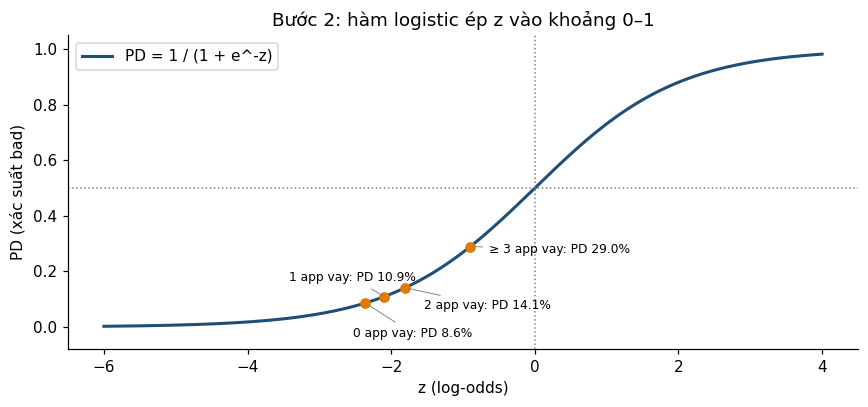

In [22]:
# Hình: hàm logistic đổi z thành PD, đánh dấu 4 nhóm số app vay
zz = np.linspace(-6, 4, 200)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(zz, 1 / (1 + np.exp(-zz)), color="#1F4E79", lw=2, label="PD = 1 / (1 + e^-z)")
names = ["0 app vay", "1 app vay", "2 app vay", "≥ 3 app vay"]
offsets = [(-8, -22), (-62, 10), (12, -14), (12, -4)]              # đặt nhãn so le cho khỏi chồng nhau
for (b, row), name, off in zip(t.iterrows(), names, offsets):
    z_, p_ = row["z = α + β × WOE"], row["PD = 1/(1+e^-z)"]
    ax.scatter(z_, p_, color="#E07B00", zorder=3)
    ax.annotate(f"{name}: PD {p_:.1%}", (z_, p_),
                textcoords="offset points", xytext=off, fontsize=8,
                arrowprops=dict(arrowstyle="-", color="grey", lw=0.6))
ax.axhline(0.5, color="grey", ls=":", lw=1); ax.axvline(0, color="grey", ls=":", lw=1)
ax.set_xlabel("z (log-odds)"); ax.set_ylabel("PD (xác suất bad)"); ax.set_ylim(-0.08, 1.05)
ax.set_title("Bước 2: hàm logistic ép z vào khoảng 0–1")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

**Với 11 biến, ý tưởng y hệt:** mỗi biến có một β riêng, cộng tất cả lại thành z:

$$z = \alpha + \beta_{\text{số app vay}} \times \text{WOE}_{\text{số app vay}} + \beta_{\text{tổng số app}} \times \text{WOE}_{\text{tổng số app}} + \dots + \beta_{11} \times \text{WOE}_{11}$$

Mỗi β bây giờ là **ảnh hưởng của biến đó khi đã tính đến 10 biến còn lại** (xem phần quy tắc 3). Hệ số của mô hình cuối cùng:

In [23]:
alpha = lr.intercept_[0]
betas = pd.Series(lr.coef_[0], index=lr_cols)
print(f"z = {alpha:.3f}")
for c, b in betas.items():
    print(f"    + ({b:.3f}) × WOE_{c}")

z = -1.925
    + (-1.312) × WOE_n_loan_apps
    + (-0.795) × WOE_n_bank_apps
    + (-1.439) × WOE_n_apps
    + (-0.468) × WOE_education
    + (-0.474) × WOE_call_pct_in_day
    + (-0.488) × WOE_call_pct_other
    + (-0.842) × WOE_call_total
    + (-0.780) × WOE_fb_age_gap
    + (-1.051) × WOE_employment_duration
    + (-0.951) × WOE_employment_type
    + (-0.749) × WOE_fb_days_since_update


**Tính tay cho 1 khách** (khách đầu tiên trong bảng ở mục 4.2): lấy WOE của khách ở từng biến, nhân với β của biến đó, rồi cộng lại.

In [24]:
k = sample.index[0]
steps = pd.DataFrame({
    "Giá trị gốc": [train.loc[k, c] for c in lr_cols],
    "Nhóm": [to_bins(train.loc[[k], c], specs[c]).iloc[0] for c in lr_cols],
    "WOE": x_woe["Train"].loc[k, lr_cols].values,
    "β (hệ số)": betas.values,
}, index=lr_cols)
steps["β × WOE"] = steps["β (hệ số)"] * steps["WOE"]

z_k = alpha + steps["β × WOE"].sum()
pd_k = 1 / (1 + np.exp(-z_k))
print(f"Tổng β × WOE      = {steps['β × WOE'].sum():.3f}")
print(f"z = α + tổng      = {alpha:.3f} + ({steps['β × WOE'].sum():.3f}) = {z_k:.3f}")
print(f"PD = 1/(1+e^-z)   = {pd_k:.2%}")
print(f"Máy tính (predict_proba) = {lr.predict_proba(x_woe['Train'].loc[[k], lr_cols])[0, 1]:.2%}   ← khớp")
print(f"Thực tế khách này: flag_bad = {train.loc[k, 'flag_bad']}")
steps.round(3)

Tổng β × WOE      = -0.287
z = α + tổng      = -1.925 + (-0.287) = -2.212
PD = 1/(1+e^-z)   = 9.87%
Máy tính (predict_proba) = 9.87%   ← khớp
Thực tế khách này: flag_bad = 0


,Giá trị gốc,Nhóm,WOE,β (hệ số),β × WOE
n_loan_apps,0,"(-inf, 0.0]",0.450,-1.312,-0.591
n_bank_apps,0,"(-inf, 0.0]",-0.246,-0.795,0.196
n_apps,12,"(-inf, 19.0]",-0.419,-1.439,0.602
education,4,"(3.0, inf]",0.393,-0.468,-0.184
call_pct_in_day,35.04,"(32.123, inf]",0.239,-0.474,-0.113
call_pct_other,27.68,"(20.0, 28.38]",0.104,-0.488,-0.051
call_total,448.0,"(185.0, inf]",-0.299,-0.842,0.251
fb_age_gap,NaN,Missing,0.198,-0.780,-0.154
employment_duration,51,"(36.0, inf]",0.199,-1.051,-0.209
employment_type,Full-time,Full-time,0.112,-0.951,-0.106


**Cách đọc:** mỗi dòng **β × WOE âm** kéo z xuống, làm khách **an toàn hơn** (khách ở nhóm an toàn của biến đó). Mỗi dòng **dương** đẩy z lên, làm khách **rủi ro hơn**. Cộng tất cả với α ra z, rồi qua hàm logistic ra PD. Scorecard ở dưới chỉ là cách viết lại đúng phép cộng này thành điểm.

**Đổi thành bảng điểm (scorecard).** Thang điểm thông dụng: **600 điểm ↔ tỷ lệ good:bad = 10:1** (PD khoảng 9%), cứ **thêm 50 điểm** thì tỷ lệ đó gấp đôi (rủi ro giảm một nửa). Đây là cách quy đổi phổ biến khi xây scorecard ("points to double the odds").

In [25]:
BASE_SCORE, BASE_ODDS, PDO = 600, 10, 50
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)

rows = []
for c, beta in zip(lr_cols, lr.coef_[0]):
    for b, w in specs[c]["table"]["woe"].items():
        pts = offset / len(lr_cols) - factor * (beta * w + lr.intercept_[0] / len(lr_cols))
        rows.append({"Biến": c, "Nhóm": b, "WOE": round(w, 2), "Điểm": round(pts)})
scorecard = pd.DataFrame(rows)
scorecard[scorecard["Biến"] == "n_loan_apps"]

,Biến,Nhóm,WOE,Điểm
0,n_loan_apps,"(-inf, 0.0]",0.45,95
1,n_loan_apps,"(0.0, 1.0]",0.19,70
2,n_loan_apps,"(1.0, 2.0]",-0.11,42
3,n_loan_apps,"(2.0, inf]",-1.01,-44


### 5.2 Gradient Boosting

Dùng toàn bộ biến (không cần WOE, mô hình tự chia nhóm). **Chống overfitting:** cây nhỏ (7 lá), mỗi lá ít nhất 500 hồ sơ, và dừng sớm khi điểm trên một phần dữ liệu để riêng không tăng nữa (early stopping) [5, chương 10].

In [26]:
ALL_COLS = NUMERIC + CATEGORICAL
categories = {c: sorted(train[c].astype(str).unique()) for c in CATEGORICAL}

def encode(frame):
    out = frame[ALL_COLS].copy()
    for c in CATEGORICAL:
        out[c] = pd.Categorical(out[c].astype(str), categories=categories[c]).codes
    return out

gb = HistGradientBoostingClassifier(
    learning_rate=0.05, max_iter=1000, max_leaf_nodes=7, min_samples_leaf=500, l2_regularization=1.0,
    categorical_features=[ALL_COLS.index(c) for c in CATEGORICAL],
    early_stopping=True, validation_fraction=0.15, n_iter_no_change=30, random_state=SEED)
gb.fit(encode(train), train["flag_bad"])
print("Số cây đã dùng:", gb.n_iter_)

Số cây đã dùng: 430


## 6. Đánh giá và chọn mô hình

### 6.1 Khả năng phân biệt: AUC, AR, KS

- **AUC**: xác suất một khách bad bị chấm rủi ro hơn một khách good (0,5 = đoán bừa, 1 = hoàn hảo) [8]. Basel trình bày Accuracy Ratio và ROC là công cụ đo khả năng phân biệt của mô hình PD [3, tr. 36–39].
- **AR** (Accuracy Ratio, giống Bài I) = 2 × AUC − 1.
- **KS**: khoảng cách lớn nhất giữa "% bad bị bắt" và "% good bị từ chối nhầm" khi trượt ngưỡng.

In [27]:
def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

preds = {
    "Logistic (scorecard)": {k: lr.predict_proba(x_woe[k][lr_cols])[:, 1] for k in sets},
    "Gradient Boosting": {k: gb.predict_proba(encode(v))[:, 1] for k, v in sets.items()},
}
perf = pd.DataFrame([
    {"Mô hình": m, "Tập": k, "AUC": roc_auc_score(sets[k]["flag_bad"], p),
     "AR": 2 * roc_auc_score(sets[k]["flag_bad"], p) - 1, "KS": ks(sets[k]["flag_bad"], p)}
    for m, by_set in preds.items() for k, p in by_set.items()])
perf.round(3)

,Mô hình,Tập,AUC,AR,KS
0,Logistic (scorecard),Train,0.734,0.468,0.344
1,Logistic (scorecard),Validation,0.743,0.487,0.354
2,Logistic (scorecard),Test OOT,0.729,0.458,0.347
3,Gradient Boosting,Train,0.826,0.652,0.491
4,Gradient Boosting,Validation,0.784,0.567,0.431
5,Gradient Boosting,Test OOT,0.773,0.547,0.406


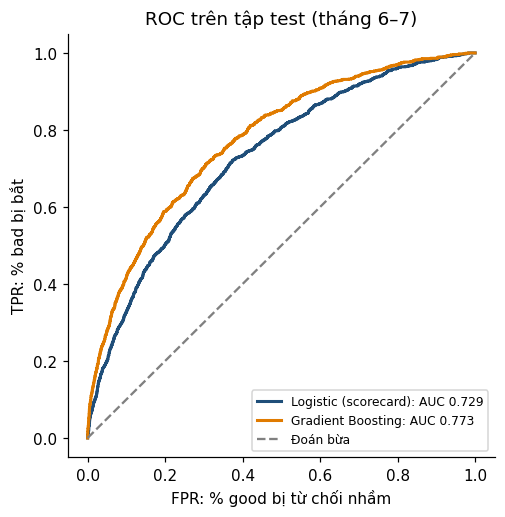

In [28]:
fig, ax = plt.subplots(figsize=(5, 5))
y_test = test["flag_bad"]
for (m, by_set), color in zip(preds.items(), ["#1F4E79", "#E07B00"]):
    fpr, tpr, _ = roc_curve(y_test, by_set["Test OOT"])
    ax.plot(fpr, tpr, color=color, lw=2, label="{}: AUC {:.3f}".format(m, roc_auc_score(y_test, by_set["Test OOT"])))
ax.plot([0, 1], [0, 1], "--", color="grey", label="Đoán bừa")
ax.set_xlabel("FPR: % good bị từ chối nhầm"); ax.set_ylabel("TPR: % bad bị bắt")
ax.set_title("ROC trên tập test (tháng 6–7)"); ax.legend(loc="lower right", fontsize=8)
plt.show()

**Nhận xét:**
- Trên tập test, **Boosting tốt hơn Logistic** khoảng 0,044 AUC (AR 0,55 so với 0,46).
- Logistic gần như không chênh giữa train và test: ổn định nhưng không quá giỏi.
- Boosting cao hơn hẳn trên train so với test, nghĩa là có **overfitting một phần**, nhưng điểm trên test set (điểm quan trọng nhất) vẫn cao hơn Logistic.

### 6.2 Hiệu chuẩn: PD dự báo có khớp thực tế không? (dùng lại Hosmer-Lemeshow của Bài I)

Chia khách trong tập test thành 10 nhóm theo PD dự báo, so tỷ lệ bad thực tế với PD trung bình của nhóm. Nếu PD đúng, HL thường quanh 10 và chỉ vượt **18,3** trong 5% trường hợp [3].

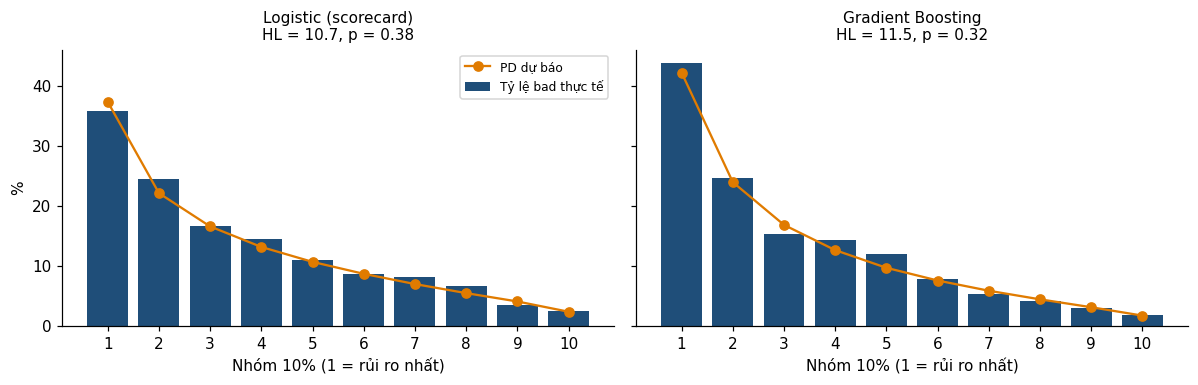

In [29]:
def decile_table(y, p):
    t = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    t["nhóm"] = pd.qcut(t["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
    g = t.groupby("nhóm", observed=True).agg(n=("y", "size"), bad=("y", "sum"), pd_tb=("p", "mean"))
    g["tỷ lệ bad"] = g["bad"] / g["n"]
    return g

def hosmer_lemeshow(g):
    e = g["n"] * g["pd_tb"]
    hl = float(((g["bad"] - e) ** 2 / (e * (1 - g["pd_tb"]))).sum())
    return hl, float(stats.chi2.sf(hl, len(g)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (m, by_set) in zip(axes, preds.items()):
    g = decile_table(y_test, by_set["Test OOT"])
    hl, p = hosmer_lemeshow(g)
    ax.bar(g.index.astype(int), g["tỷ lệ bad"] * 100, color="#1F4E79", label="Tỷ lệ bad thực tế")
    ax.plot(g.index.astype(int), g["pd_tb"] * 100, "o-", color="#E07B00", label="PD dự báo")
    ax.set_title("{}\nHL = {:.1f}, p = {:.2f}".format(m, hl, p), fontsize=10)
    ax.set_xlabel("Nhóm 10% (1 = rủi ro nhất)"); ax.set_xticks(range(1, 11))
axes[0].set_ylabel("%"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Nhận xét:** tỷ lệ bad giảm đều từ nhóm 1 đến nhóm 10 (thứ tự đúng), và PD dự báo bám sát thực tế. HL của cả hai mô hình **dưới ngưỡng 18,3**, nên PD được hiệu chuẩn tốt. Đây là điểm khác biệt so với mô hình trong Bài I.

### 6.3 Độ ổn định: PSI

PSI đo xem phân phối điểm có bị dịch chuyển giữa lúc xây mô hình (train) và lúc dùng (test) không. Quy ước: < 0,1 ổn định, 0,1–0,25 cần theo dõi, > 0,25 dịch chuyển lớn. Đây là quy ước thực hành trong ngành [1]; tính chất thống kê của PSI được phân tích trong [12].

In [30]:
def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected) + 1e-6
    a = np.histogram(actual, edges)[0] / len(actual) + 1e-6
    return float(np.sum((a - e) * np.log(a / e)))

{m: round(psi(by_set["Train"], by_set["Test OOT"]), 4) for m, by_set in preds.items()}

{'Logistic (scorecard)': 0.0046, 'Gradient Boosting': 0.0028}

### 6.4 Mô hình dựa vào đâu để quyết định?

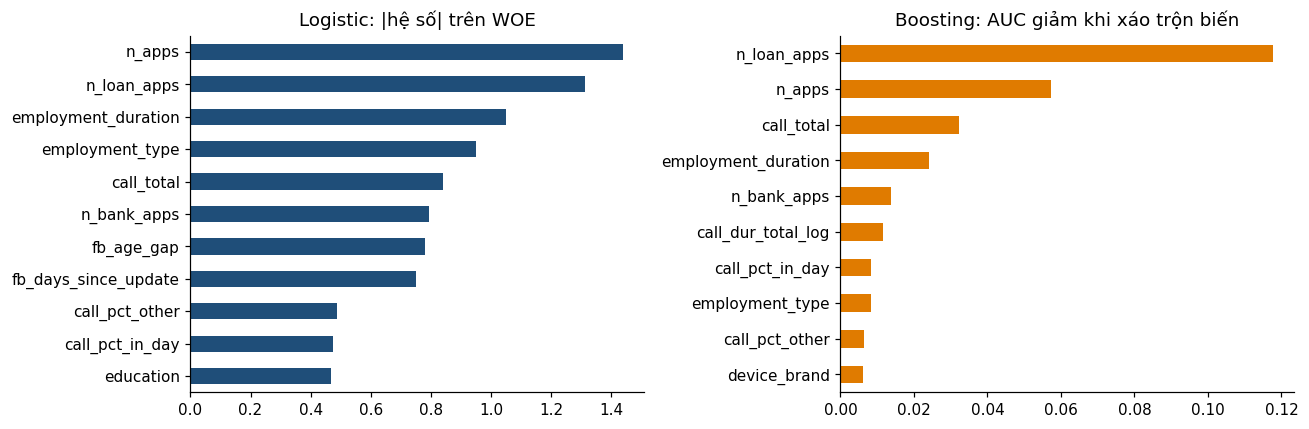

In [31]:
imp = permutation_importance(gb, encode(valid), valid["flag_bad"], scoring="roc_auc", n_repeats=5, random_state=SEED)
gb_imp = pd.Series(imp.importances_mean, index=ALL_COLS).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
coef.abs().sort_values().plot.barh(ax=axes[0], color="#1F4E79", title="Logistic: |hệ số| trên WOE")
gb_imp.sort_values().plot.barh(ax=axes[1], color="#E07B00", title="Boosting: AUC giảm khi xáo trộn biến")
plt.tight_layout(); plt.show()

Hai mô hình đồng ý về các biến quan trọng nhất: **số app vay, tổng số app, hoạt động gọi điện, thâm niên làm việc**. Boosting không dựa vào biến "lạ" mà khai thác cùng các tín hiệu, chỉ chi tiết hơn.

### 6.5 Kiểm tra thêm: chia theo thời gian hay chia ngẫu nhiên đều các tháng?

So sánh hai cách tạo test set, với **cùng số hồ sơ test** và **cùng toàn bộ quy trình** (chia nhóm WOE, chọn biến, 2 mô hình):

| | Training + Validation | Test set |
|---|---|---|
| **Cách A – theo thời gian** (cách đang dùng) | Tháng 1–5 | Tháng 6–7 |
| **Cách B – ngẫu nhiên đều các tháng** | Lấy ngẫu nhiên từ cả 7 tháng | Lấy ngẫu nhiên từ cả 7 tháng, giữ đúng tỷ lệ từng tháng và tỷ lệ bad |

In [32]:
def run_pipeline(train, test):
    """Chạy lại toàn bộ bước 4-5 trên một cách chia dữ liệu, trả về AUC trên test set."""
    sp = {c: fit_binning(train[c], train["flag_bad"], "numeric") for c in NUMERIC}
    sp.update({c: fit_binning(train[c], train["flag_bad"], "categorical") for c in CATEGORICAL})
    xw_train = woe_transform(train, sp, NUMERIC + CATEGORICAL)
    xw_test = woe_transform(test, sp, NUMERIC + CATEGORICAL)

    # Chọn biến: IV >= 0,02 và không tương quan cao với biến đã chọn
    iv_ = pd.Series({c: s["iv"] for c, s in sp.items()}).sort_values(ascending=False)
    corr_ = xw_train.corr().abs()
    cols_ = []
    for c in iv_.index:
        if iv_[c] >= 0.02 and not any(corr_.loc[c, k] > 0.6 for k in cols_):
            cols_.append(c)
    # Logistic: loại dần biến có hệ số ngược dấu
    while True:
        m_lr = LogisticRegression(C=1.0, max_iter=2000).fit(xw_train[cols_], train["flag_bad"])
        coef_ = pd.Series(m_lr.coef_[0], index=cols_)
        if (coef_ <= 0).all():
            break
        cols_.remove(coef_.idxmax())

    cats_ = {c: sorted(train[c].astype(str).unique()) for c in CATEGORICAL}
    def enc(frame):
        out = frame[ALL_COLS].copy()
        for c in CATEGORICAL:
            out[c] = pd.Categorical(out[c].astype(str), categories=cats_[c]).codes
        return out
    m_gb = HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=1000, max_leaf_nodes=7, min_samples_leaf=500, l2_regularization=1.0,
        categorical_features=[ALL_COLS.index(c) for c in CATEGORICAL],
        early_stopping=True, validation_fraction=0.15, n_iter_no_change=30, random_state=SEED)
    m_gb.fit(enc(train), train["flag_bad"])

    y = test["flag_bad"]
    auc_lr = roc_auc_score(y, m_lr.predict_proba(xw_test[cols_])[:, 1])
    auc_gb = roc_auc_score(y, m_gb.predict_proba(enc(test))[:, 1])
    return {"Logistic (scorecard)": auc_lr, "Gradient Boosting": auc_gb}

# Cách A: theo thời gian (train / test giống mục 3)
auc_time = run_pipeline(train, test)

# Cách B: ngẫu nhiên đều các tháng, test set cùng kích thước với cách A.
# Chia ngẫu nhiên 5 lần (5 seed khác nhau) để xem kết quả dao động bao nhiêu.
strata = df["month"] + "_" + df["flag_bad"].astype(str)        # giữ tỷ lệ từng tháng và tỷ lệ bad
random_runs = []
for seed in range(5):
    dev_r, test_r = train_test_split(df, test_size=len(test), stratify=strata, random_state=seed)
    train_r, _ = train_test_split(dev_r, test_size=0.25, stratify=dev_r["flag_bad"], random_state=seed)
    random_runs.append(run_pipeline(train_r, test_r))
random_runs = pd.DataFrame(random_runs)

compare = pd.DataFrame({
    "A – theo thời gian": pd.Series(auc_time),
    "B – ngẫu nhiên (trung bình 5 lần)": random_runs.mean(),
    "B – thấp nhất": random_runs.min(),
    "B – cao nhất": random_runs.max(),
}).T
compare.index.name = "AUC trên test set"
compare.round(3)

,Logistic (scorecard),Gradient Boosting
AUC trên test set,,
A – theo thời gian,0.729,0.773
B – ngẫu nhiên (trung bình 5 lần),0.732,0.771
B – thấp nhất,0.724,0.764
B – cao nhất,0.736,0.781


In [33]:
# Test set của mỗi cách gồm hồ sơ tháng nào? (cách B: lần chia cuối cùng)
months_in_test = pd.DataFrame({
    "A – theo thời gian": test["month"].value_counts(normalize=True),
    "B – ngẫu nhiên đều các tháng": test_r["month"].value_counts(normalize=True),
}).fillna(0).sort_index()
(months_in_test * 100).round(0).astype(int).astype(str) + "%"

,A – theo thời gian,B – ngẫu nhiên đều các tháng
month,,
2018-01,0%,11%
2018-02,0%,14%
2018-03,0%,15%
2018-04,0%,17%
2018-05,0%,21%
2018-06,68%,15%
2018-07,32%,7%


**Nhận xét:**
- Chia ngẫu nhiên 5 lần thì AUC dao động khoảng **0,72–0,74** (Logistic) và **0,76–0,78** (Gradient Boosting). Kết quả của cách chia theo thời gian (0,729 và 0,773) **nằm trong khoảng đó**. Nghĩa là hai cách cho kết quả tương đương, và cách chia theo thời gian không làm kết quả đẹp lên hay xấu đi một cách giả tạo.
- Khác biệt nằm ở **câu hỏi mà mỗi cách trả lời**. Cách B kiểm tra mô hình trên khách có cùng kiểu với lúc học (test set có đủ 7 tháng). Cách A kiểm tra mô hình trên khách **tương lai** mà nó chưa từng thấy, giống lúc ngân hàng dùng thật.
- Vì vậy bài giữ **cách A làm kết quả chính**. Mục 6.6 cho thấy khách tháng 6–7 thật sự khác khách tháng 1–5.

### 6.6 Khách tháng 6–7 khác gì? Ví dụ: dữ liệu Facebook

In [34]:
fb_by_month = pd.crosstab(df["month"], df["has_fb"], normalize="index").rename(
    columns={"Yes": "Có Facebook", "No": "Không có Facebook"})
(fb_by_month * 100).round(0).astype(int).astype(str) + "%"

has_fb,Không có Facebook,Có Facebook
month,,
2018-01,0%,100%
2018-02,0%,100%
2018-03,0%,100%
2018-04,0%,100%
2018-05,0%,100%
2018-06,5%,95%
2018-07,39%,61%


**Nhận xét:**
- Tháng 1–5: **100%** hồ sơ có dữ liệu Facebook. Tháng 6 còn khoảng 95%, tháng 7 chỉ còn khoảng **61%**. Có thể cách thu thập dữ liệu đã thay đổi (dữ liệu không cho biết lý do).
- Nếu chia ngẫu nhiên (cách B), những hồ sơ không có Facebook bị trộn vào cả training lẫn test, nên **không thấy được thay đổi này**. Chia theo thời gian (cách A) giúp phát hiện nó và kiểm tra mô hình có chịu được hay không. Ở bài này mô hình vẫn chịu được: AUC trên test set vẫn đạt 0,73 / 0,77.
- Nếu đưa mô hình vào dùng, cần theo dõi tỷ lệ thiếu dữ liệu Facebook, vì scorecard có dùng 2 biến Facebook.

## Kết luận

| | Logistic (scorecard) | Gradient Boosting |
|---|---|---|
| AUC trên test (tháng 6–7) | 0,729 | **0,773** |
| AR trên test | 0,46 | **0,55** |
| Hiệu chuẩn (HL) | Đạt | Đạt |
| Ổn định (PSI) | Đạt | Đạt |
| Dễ giải thích | **Rất dễ** | Khó hơn |

**Đề xuất:** dùng **Gradient Boosting** làm mô hình chính vì dự báo tốt hơn rõ rệt trên dữ liệu tương lai, vẫn ổn định và hiệu chuẩn tốt. Giữ **Logistic scorecard** làm mô hình đối chứng, và là phương án thay thế khi cần giải thích từng điểm số (ví dụ lý do từ chối).

**Tín hiệu mạnh nhất:** số app vay trong máy. Các demographic features như tuổi, lương, giới tính gần như không có sức dự báo trong dữ liệu này.

### Hạn chế và bước tiếp theo
- Cách đếm app vay còn thô (dựa trên từ khóa trong tên app).
- Chưa dò tham số có hệ thống cho Boosting (ví dụ cross-validation theo thời gian).
- Chưa giải thích được từng khách hàng (cần SHAP [11]).
- Chưa biết "bad" được định nghĩa là quá hạn bao nhiêu ngày; ngưỡng duyệt cần chọn cùng nghiệp vụ.
- Dữ liệu chỉ có người đã được duyệt vay, nên mô hình chưa thấy người bị từ chối (reject inference [2, tr. 187]).
- Chưa kiểm tra tính công bằng giữa các nhóm (ví dụ giới tính).
- Tháng 7 có khoảng 39% hồ sơ không có dữ liệu Facebook (mục 6.6). Cần theo dõi vì scorecard dùng 2 biến Facebook.
- **Đã tìm ra, chưa sửa:** scorecard chấm PD cho khách **không có Facebook** cao hơn thực tế (PD dự báo trung bình 13,5%, tỷ lệ bad thực tế 10,0% trên test set). Nguyên nhân: nhóm "Missing" của `fb_days_since_update` chỉ có **2 hồ sơ** trong training set (tháng 1–5 ai cũng có Facebook), nên WOE của nhóm này không đáng tin, trong khi tháng 7 có 39% hồ sơ rơi vào nhóm này. Gradient Boosting không bị lỗi này (PD dự báo 10,3%). **Cách sửa:** nhóm nào quá ít hồ sơ (ví dụ < 100) thì gán WOE = 0 (trung tính), hoặc hiệu chỉnh lại PD cho nhóm này.
- Hồ sơ tháng 7 mới nhất nên có thể chưa đủ thời gian để lộ ra là bad. Tỷ lệ bad tháng 7 thấp hơn tháng 6 có thể một phần vì lý do này.
- Trước khi dùng thật, nên huấn luyện lại mô hình trên cả 7 tháng để học được thay đổi gần nhất.

## Tài liệu tham khảo

Chỉ giữ các nguồn đã kiểm chứng được nội dung (toàn văn, abstract, hoặc nguồn thứ cấp).

**Credit scoring (WOE, IV, scorecard)**

1. Siddiqi, N. (2006). *Credit Risk Scorecards: Developing and Implementing Intelligent Credit Scoring*. Wiley. (Bản 2: *Intelligent Credit Scoring*, 2017.)
2. Delamaire, L. (2012). *Implementing a credit risk management system based on innovative scoring techniques* (Doctoral thesis). University of Birmingham. http://etheses.bham.ac.uk/3344/ (tr. 152: cách đọc IV và dấu của biến; tr. 187: reject inference)

**Kiểm định mô hình PD**

3. Basel Committee on Banking Supervision (2005). *Studies on the validation of internal rating systems* (Working Paper No. 14). Bank for International Settlements.

**Logistic Regression và Gradient Boosting**

4. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer. Bản PDF miễn phí: https://www.statlearning.com
5. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.
6. Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics, 29*(5), 1189–1232.
7. Ke, G., Meng, Q., Finley, T., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems 30*.

**Đánh giá, rò rỉ dữ liệu, giải thích mô hình**

8. Hanley, J. A., & McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology, 143*(1), 29–36.
9. Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21.
10. Lessmann, S., Baesens, B., Seow, H.-V., & Thomas, L. C. (2015). Benchmarking state-of-the-art classification algorithms for credit scoring: An update of research. *European Journal of Operational Research, 247*(1), 124–136.
11. Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems 30*.

**Độ ổn định (PSI)**

12. Yurdakul, B., & Naranjo, J. D. (2020). Statistical properties of the population stability index. *Journal of Risk Model Validation*. https://doi.org/10.21314/JRMV.2020.227

**Hồi quy nhiều biến (phần dư)**

13. Frisch, R., & Waugh, F. V. (1933). Partial time regressions as compared with individual trends. *Econometrica, 1*(4), 387–401.
14. Lovell, M. C. (1963). Seasonal adjustment of economic time series and multiple regression analysis. *Journal of the American Statistical Association, 58*(304), 993–1010.